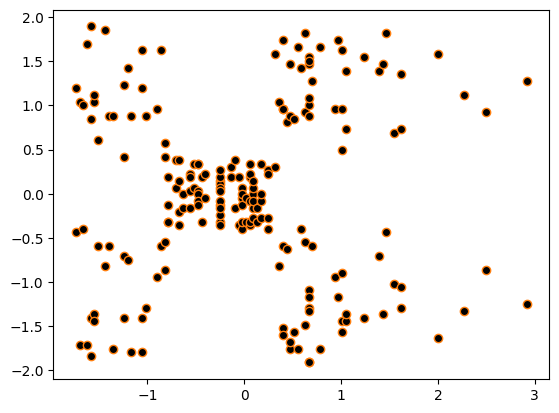

In [14]:
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

dataset=pd.read_csv("KMeans.csv")

X=dataset.iloc[:,[1,2]].values

from sklearn.preprocessing import StandardScaler
X=StandardScaler().fit_transform(X)


from sklearn.cluster import DBSCAN
dbs=DBSCAN(eps=0.3,min_samples=200).fit(X)
labels=dbs.labels_
labels

dbs.core_sample_indices_
core_samples=np.zeros_like(dbs.labels_,dtype=bool)
core_samples

core_samples[dbs.core_sample_indices_]=True
core_samples

n_clusters=len(set(labels))-1
n_clusters

list(labels).count(-1)
colours=[plt.cm.Spectral(i)for i in np.linspace(0,1,
                          len(set(labels)))]
colours

for lab,col in zip(list(set(labels)),colours):
  if lab==-1:
    col=[0,0,0,1]
  class_members=(labels==lab)
  datapoint=X[class_members & core_samples]
  #core points
  plt.plot(datapoint[:,0],datapoint[:,1], 'o',
           markerfacecolor=tuple(col),markersize=14)

  datapoint=X[class_members & ~core_samples] #boundary
  #core points
  plt.plot(datapoint[:,0],datapoint[:,1], 'o',
           markerfacecolor=tuple(col),markersize=6)

plt.show()